In [105]:
!uv pip install opencv-python numpy matplotlib

Using Python 3.12.7 environment at: /Users/hydroxide/Desktop/Projects/badminton-analysis/.venv
Audited 3 packages in 35ms


In [106]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

## Playing Around with CV2

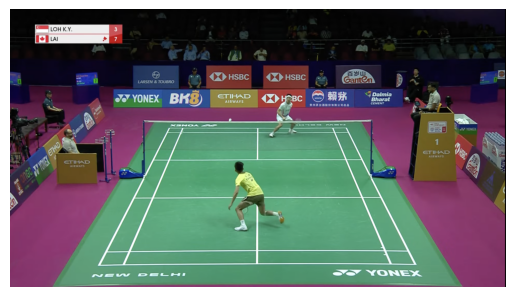

In [172]:
frame = cv2.imread('../test_data/shot1.png')
plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

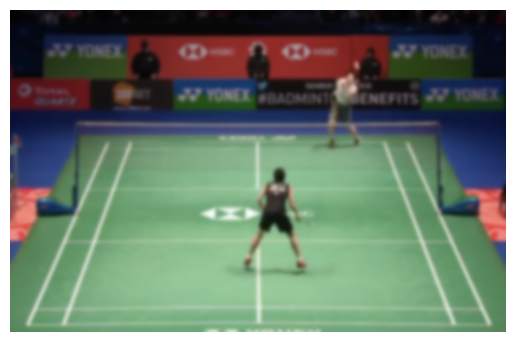

In [108]:
gaussian = cv2.GaussianBlur(frame, (35, 35), 0.0)
plt.imshow(cv2.cvtColor(gaussian, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

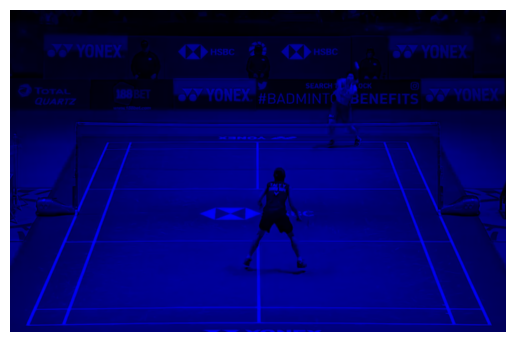

In [109]:
# b,g,r = cv2.split(frame)

r = frame.copy()
r[:,:,0:2] = 0

b = frame.copy()
b[:,:,1:3] = 0

g = frame.copy()
g[:,:,0:3:2] = 0

assert r[0,0,0] == 0
assert r[0,0,1] == 0

assert g[0,0,0] == 0
assert g[0,0,2] == 0

assert b[0,0,1] == 0
assert b[0,0,2] == 0

plt.imshow(cv2.cvtColor(b, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

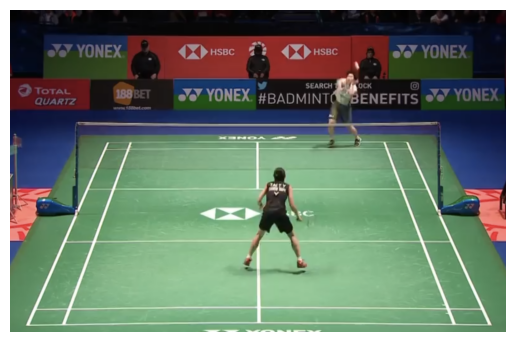

In [110]:
img_reconstructed = r + g + b
plt.imshow(cv2.cvtColor(img_reconstructed, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

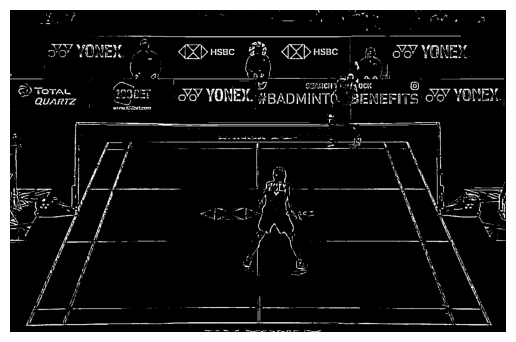

In [165]:
hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)

s = hsv[:, :, 1].astype(np.float32)
v = hsv[:, :, 2].astype(np.float32)

# Estimate local background properties
local_s = cv2.GaussianBlur(s, (11, 11), 0)
local_v = cv2.GaussianBlur(v, (11, 11), 0)

# Detect pixels that differ from their surroundings
low_saturation = s < local_s - 5
high_brightness = v > local_v + 5

mask = (low_saturation & high_brightness).astype(np.uint8)

plt.imshow(mask, cmap="gray")
plt.axis("off")
plt.show()

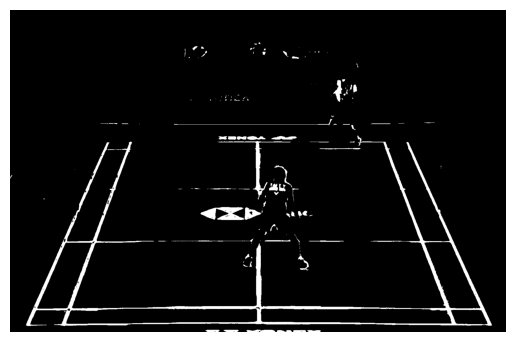

In [171]:
hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)

lower = [0, 0, 150]
upper = [75, 50, 255]

mask = cv2.inRange(
    hsv,
    np.array(lower),
    np.array(upper)
)

plt.imshow(mask, cmap="gray")
plt.axis("off")
plt.show()